# Challenge: 1D Convolutional Neural Networks on MNIST-1D

**ARTE 4110U — Deep Learning Architecture and Algorithms**

**Name:** Joao Pedro Minari
**Student ID:** [removed]

In this challenge, you will build and train a 1D convolutional neural network to classify MNIST-1D signals into digits 0–9. You will implement the data loading, model, training, and validation code yourself.

**Learning goals:** work with 1D signals and tensor shapes; apply kernels, channels, stride, and padding; calculate output lengths and parameter counts; train and evaluate a Conv1D classifier.

Complete all **TODOs** and answer the questions in the notebook. Use PyTorch; do not use Conv2d. Run your cells in order and submit the completed `.ipynb` file with outputs on Canvas. This is individual work. Include an AI-use disclosure at the end. A GPU is not required.

## 1. Load and explore MNIST-1D

MNIST-1D is a synthetic dataset of **one-dimensional signals** representing 10 digit classes; it is not the 28 × 28 image dataset flattened into a vector.

Use the [official MNIST-1D repository](https://github.com/greydanus/mnist1d). For a common dataset across students, use the repository’s frozen dataset: [`mnist1d_data.pkl`](https://github.com/greydanus/mnist1d/raw/master/mnist1d_data.pkl). The repository README shows how to download and load it. The dictionary contains `x`, `y` (training data) and `x_test`, `y_test` (test data). Downloading requires an internet connection; once downloaded, the file can be reused locally.

**TODO**
1. Import the packages you need and load the frozen dataset.
2. Print the shapes of the training and test inputs and labels, and the unique class labels.
3. Plot at least five training signals with their labels. Label the axes.
4. Explain what one sample and one class label represent.

Train inputs: (4000, 40) Train labels: (4000,)
Test inputs:  (1000, 40) Test labels:  (1000,)
Classes: [0 1 2 3 4 5 6 7 8 9]


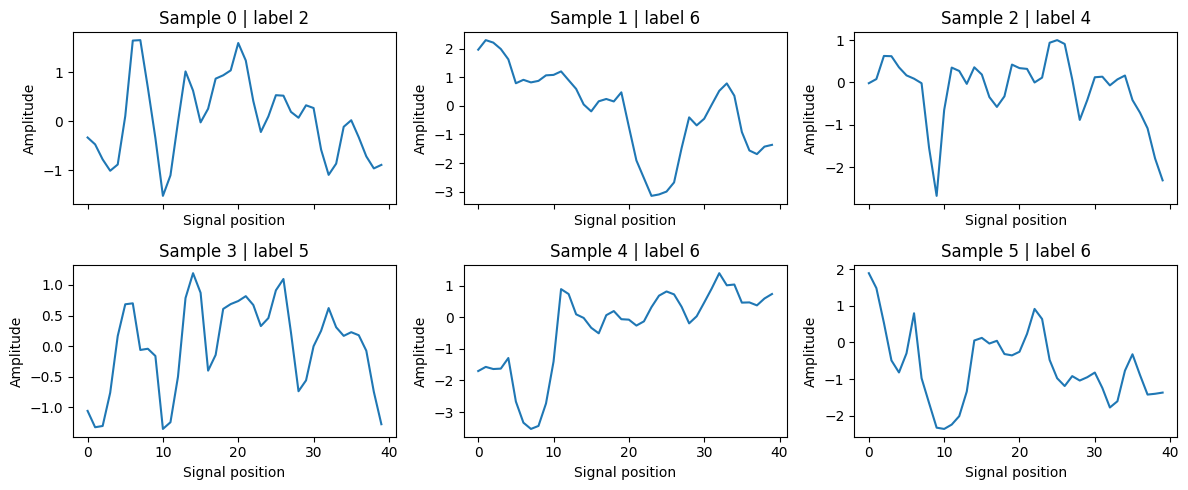

In [1]:
# TODO: Write your code here
import pickle
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

data_path = Path("mnist1d_data.pkl")
if not data_path.exists():
    url = "https://github.com/greydanus/mnist1d/raw/master/mnist1d_data.pkl"
    urlretrieve(url, data_path)

with data_path.open("rb") as f:
    data = pickle.load(f)

x, y = np.asarray(data["x"]), np.asarray(data["y"])
x_test, y_test = np.asarray(data["x_test"]), np.asarray(data["y_test"])
print("Train inputs:", x.shape, "Train labels:", y.shape)
print("Test inputs: ", x_test.shape, "Test labels: ", y_test.shape)
print("Classes:", np.unique(y))

fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharex=True)
for idx, ax in enumerate(axes.flat):
    ax.plot(np.arange(x.shape[1]), x[idx])
    ax.set_title(f"Sample {idx} | label {y[idx]}")
    ax.set_xlabel("Signal position")
    ax.set_ylabel("Amplitude")
plt.tight_layout()
plt.show()

**Your answer:** One sample is a one-dimensional synthetic signal made of amplitude values at successive positions (40 values in the frozen dataset). One class label is an integer from 0 to 9 indicating which digit-pattern class produced the signal. These are not flattened handwritten digit images.

## 2. Prepare the data

**TODO**
1. Split the original training set into **training (80%) and validation (20%)** using a fixed random seed. Keep the provided test set separate.
2. Convert inputs to floating-point tensors and labels to integer class-index tensors (`torch.long`).
3. Prepare `DataLoader`s for training, validation, and test. Shuffle only the training loader.
4. Ensure each batch has the shape **(batch size, channels, signal length)** expected by `nn.Conv1d`. Each signal has one input channel. Print one batch’s input and label shapes.

If you normalize the signals, compute any normalization statistics using the training split only and apply the same transformation to validation and test.

In [2]:
# TODO: Write your code here
BATCH_SIZE = 64

indices = np.random.default_rng(SEED).permutation(len(x))
split = int(0.8 * len(indices))
train_idx, val_idx = indices[:split], indices[split:]

x_train = torch.tensor(x[train_idx], dtype=torch.float32).unsqueeze(1)
y_train = torch.tensor(y[train_idx], dtype=torch.long)
x_val = torch.tensor(x[val_idx], dtype=torch.float32).unsqueeze(1)
y_val = torch.tensor(y[val_idx], dtype=torch.long)
x_test_tensor = torch.tensor(x_test, dtype=torch.float32).unsqueeze(1)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)


train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(x_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(x_test_tensor, y_test_tensor), batch_size=BATCH_SIZE, shuffle=False)

batch_x, batch_y = next(iter(train_loader))
print("Training samples:", len(train_idx), "Validation samples:", len(val_idx), "Test samples:", len(x_test))
print("Input batch shape:", tuple(batch_x.shape))
print("Label batch shape:", tuple(batch_y.shape))

Training samples: 3200 Validation samples: 800 Test samples: 1000
Input batch shape: (64, 1, 40)
Label batch shape: (64,)


**Questions**

- What is the shape of one input batch? What does each dimension represent?
- Why should the test set not be used to choose your model or hyperparameters?

**Your answer:**

With batch size 64 and the frozen dataset, an ordinary full input batch has shape (64, 1, 40): 64 samples, 1 signal channel per sample, and 40 positions in each signal. The labels have shape (64,), one integer class index per sample. A final batch may contain fewer than 64 samples.

The test set must be held out to obtain a fair estimate of generalization to unseen data. Selecting the architecture, learning rate, or epoch based on test results would leak test information into model selection and make the reported test accuracy overly optimistic.

## 3. Design and implement your Conv1D model

**TODO**
1. Build a PyTorch model with **at least two `nn.Conv1d` layers**, nonlinear activation functions, and a final classification layer with 10 outputs. Choose and document the number of channels, kernel size, stride, and padding for each convolution.
2. Convert the convolutional output into a suitable input for the final classification layer. You may use flattening.
3. Print the model and its total number of trainable parameters.
4. Pass one batch through the model and print the output shape. Return **raw logits**; do not apply softmax before `CrossEntropyLoss`.

For a convolution with input length $L_{in}$, kernel size $K$, padding $P$, stride $S$, and dilation $D$, the output length is:

$$L_{out}=\left\lfloor\frac{L_{in}+2P-D(K-1)-1}{S}+1\right\rfloor.$$

For a Conv1D layer with bias, the number of trainable parameters is $(C_{in}K+1)C_{out}$.

In [3]:
# TODO: Write your code here
class Conv1DClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=16, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.Conv1d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(8),
        )
        self.classifier = nn.Linear(32 * 8, 10)

    def forward(self, inputs):
        features = self.features(inputs)
        return self.classifier(torch.flatten(features, start_dim=1))  # raw logits

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Conv1DClassifier().to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
with torch.no_grad():
    layer1 = model.features[0](batch_x.to(device))
    layer2 = model.features[2](torch.relu(layer1))
    logits = model(batch_x.to(device))
print("Conv 1 output (B,C,L):", tuple(layer1.shape))
print("Conv 2 output (B,C,L):", tuple(layer2.shape))
print("Classifier output (B,10):", tuple(logits.shape))
print("First convolution parameter count:", sum(p.numel() for p in model.features[0].parameters()))

Conv1DClassifier(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (3): ReLU()
    (4): AdaptiveAvgPool1d(output_size=8)
  )
  (classifier): Linear(in_features=256, out_features=10, bias=True)
)
Trainable parameters: 4234
Conv 1 output (B,C,L): (64, 16, 40)
Conv 2 output (B,C,L): (64, 32, 40)
Classifier output (B,10): (64, 10)
First convolution parameter count: 96


**Questions**

- For each of your convolutional layers, show the input and output shapes (excluding batch size), and calculate the output length. Check your calculations against the shapes observed in code.
- Calculate the number of trainable parameters in your **first convolutional layer**, including bias if used. Check it against PyTorch.
- What does each output channel represent? Explain how the same kernel is used at different positions.

**Your answer:**

Conv1: Input (1, 40) → output (16, 40). With kernel size 5, stride 1, padding 2, and dilation 1, the output length is floor((40 + 2×2 − (5−1) − 1)/1 + 1) = 40.

Conv2: Input (16, 40) → output (32, 40). With kernel size 3, stride 1, padding 1, and dilation 1, the output length is floor((40 + 2×1 − (3−1) − 1)/1 + 1) = 40.

Adaptive average pooling then changes the length from 40 to 8, so flattening produces 32×8 = 256 features for the final linear classifier. The code prints the actual shapes to check these calculations.

The first convolution has (1×5 + 1)×16 = 96 trainable parameters, including 16 biases; the code independently checks this. The second has (16×3 + 1)×32 = 1,568 parameters, and the classifier has (256 + 1)×10 = 2,570, for 4,234 total.

Each output channel is one learned feature map: a filter can respond to a different local pattern in the signal. The same filter weights slide along every position, creating responses to that pattern regardless of where it appears (aside from boundary effects).

## 4. Train and validate

**TODO**
1. Choose a loss function and optimizer appropriate for this classification task. State your choices and learning rate.
2. Implement a training loop and a separate validation loop. Use `model.train()` during training and `model.eval()` with `torch.no_grad()` during validation.
3. For each epoch, record and display the average training loss, validation loss, and validation accuracy. Calculate epoch metrics over all samples, including the final partial batch.
4. Plot training and validation loss versus epoch, and validation accuracy versus epoch.
5. Save the model weights from the epoch with the **highest validation accuracy**. You may choose your number of epochs and other hyperparameters using validation results.

Start with a modest number of epochs and adjust if needed. There is no required accuracy threshold; focus on a correct implementation and thoughtful analysis.

Epoch 01/15: train loss=2.1891, val loss=1.9936, val accuracy=20.75%
Epoch 02/15: train loss=1.8114, val loss=1.7361, val accuracy=31.13%
Epoch 03/15: train loss=1.6563, val loss=1.6243, val accuracy=34.88%
Epoch 04/15: train loss=1.5772, val loss=1.5556, val accuracy=37.62%
Epoch 05/15: train loss=1.5170, val loss=1.5185, val accuracy=40.38%
Epoch 06/15: train loss=1.4769, val loss=1.4751, val accuracy=42.50%
Epoch 07/15: train loss=1.4406, val loss=1.4626, val accuracy=42.88%
Epoch 08/15: train loss=1.4229, val loss=1.4371, val accuracy=43.62%
Epoch 09/15: train loss=1.3963, val loss=1.4147, val accuracy=46.38%
Epoch 10/15: train loss=1.3741, val loss=1.3937, val accuracy=45.50%
Epoch 11/15: train loss=1.3461, val loss=1.3742, val accuracy=46.25%
Epoch 12/15: train loss=1.3252, val loss=1.3353, val accuracy=50.00%
Epoch 13/15: train loss=1.2900, val loss=1.3266, val accuracy=50.38%
Epoch 14/15: train loss=1.2661, val loss=1.2867, val accuracy=52.12%
Epoch 15/15: train loss=1.2350, va

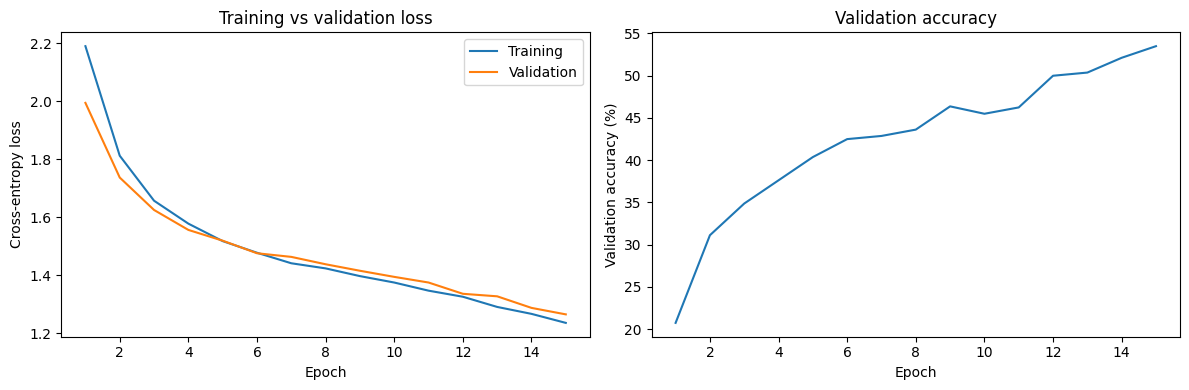

Selected epoch: 15 | best validation accuracy: 53.50%
Model weights saved to: mnist1d_best_conv1d.pt


In [4]:
# TODO: Write your code here
criterion = nn.CrossEntropyLoss()
LEARNING_RATE = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
EPOCHS = 15

history = {"train_loss": [], "val_loss": [], "val_accuracy": []}
best_val_accuracy = -1.0
best_epoch = None
checkpoint_path = Path("mnist1d_best_conv1d.pt")

for epoch in range(1, EPOCHS + 1):
    model.train()
    training_loss_sum = 0.0
    training_count = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        training_loss_sum += loss.item() * yb.size(0)
        training_count += yb.size(0)
    avg_train_loss = training_loss_sum / training_count

    model.eval()
    validation_loss_sum = 0.0
    validation_correct = 0
    validation_count = 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            validation_loss_sum += loss.item() * yb.size(0)
            validation_correct += (logits.argmax(dim=1) == yb).sum().item()
            validation_count += yb.size(0)
    avg_val_loss = validation_loss_sum / validation_count
    val_accuracy = validation_correct / validation_count

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["val_accuracy"].append(val_accuracy)
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = epoch
        torch.save(model.state_dict(), checkpoint_path)
    print(f"Epoch {epoch:02d}/{EPOCHS}: train loss={avg_train_loss:.4f}, "
          f"val loss={avg_val_loss:.4f}, val accuracy={val_accuracy:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epoch_numbers = range(1, EPOCHS + 1)
axes[0].plot(epoch_numbers, history["train_loss"], label="Training")
axes[0].plot(epoch_numbers, history["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Training vs validation loss")
axes[0].legend()
axes[1].plot(epoch_numbers, np.array(history["val_accuracy"]) * 100)
axes[1].set(xlabel="Epoch", ylabel="Validation accuracy (%)", title="Validation accuracy")
plt.tight_layout()
plt.show()
print(f"Selected epoch: {best_epoch} | best validation accuracy: {best_val_accuracy:.2%}")
print(f"Model weights saved to: {checkpoint_path}")

**Questions**

- Why are the activation function and loss function appropriate for your model?
- What do your training and validation curves suggest? Is there evidence of underfitting or overfitting?

**Your answer:**

Activation: ReLU introduces nonlinearity so stacked convolutions can learn more than one linear transformation, it is simple and works well with gradient-based training.

Loss: Cross-entropy is appropriate for ten mutually exclusive digit classes; PyTorch's CrossEntropyLoss applies the necessary log-softmax internally, so the network returns raw logits rather than probabilities. I used Adam with learning rate 0.001.

Both training and validation loss decrease steadily over the 15 epochs, while validation accuracy improves from 20.75% to 53.50%. This shows that the model is learning useful patterns from the data. There is no clear evidence of overfitting because validation loss continues to decrease alongside training loss. However, the relatively low accuracy and continued improvement suggest that the model may still be underfitting and could benefit from more training epochs or a more complex architecture.

## 5. Evaluate and interpret

**TODO**
1. Load the weights selected using validation accuracy. Evaluate the model on the untouched test set and report **test accuracy**.
2. Display at least five test signals with their true and predicted labels, including a misclassified example if one exists.
3. Explain one possible reason for an observed error. Do not change your model based on test results.

Selected epoch: 15
Best validation accuracy: 53.50%
Untouched test accuracy: 51.50% (515/1000)


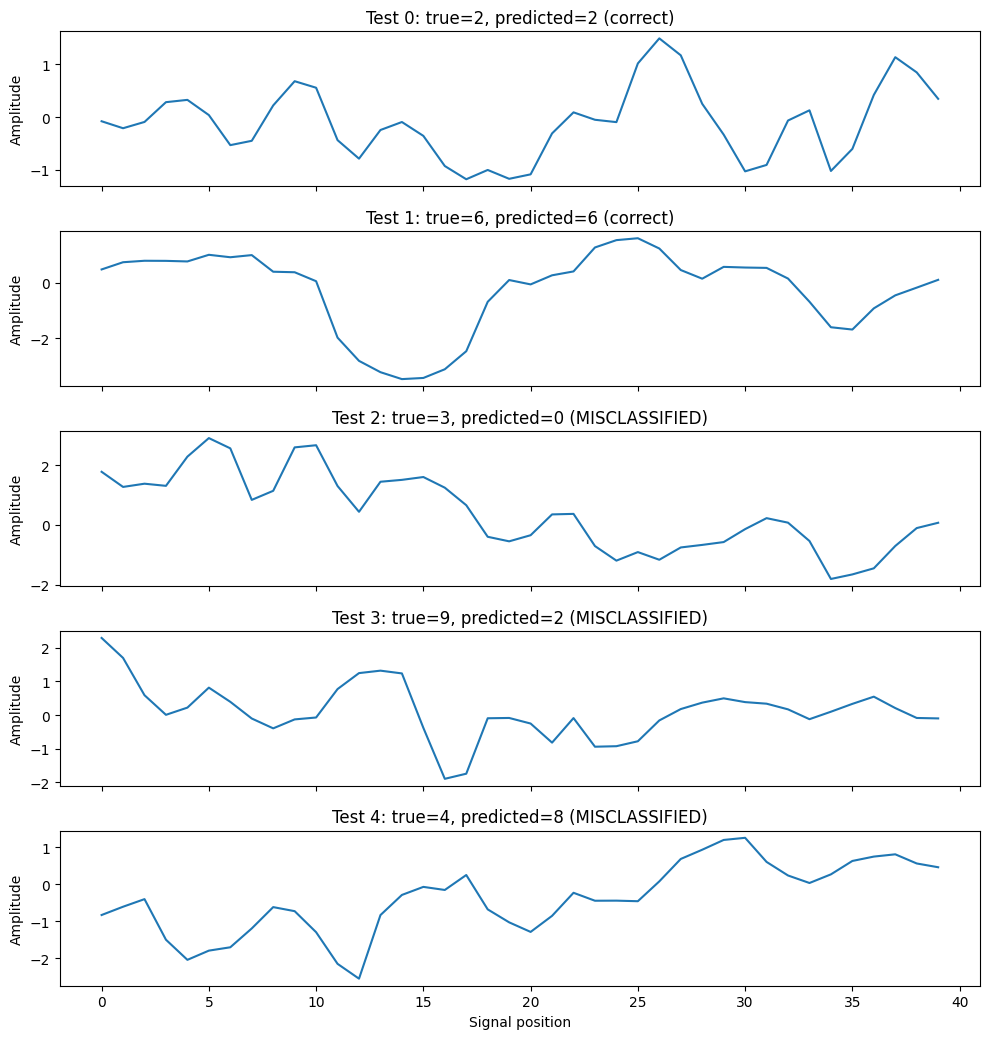

Example error: sample 2 was class 3 but predicted as 0.
A possible explanation is noise or a shifted/distorted pattern resembling another class.


In [5]:
# TODO: Write your code here
model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
model.eval()
test_correct = 0
test_count = 0
all_predictions = []
with torch.no_grad():
    for xb, yb in test_loader:
        predicted = model(xb.to(device)).argmax(dim=1).cpu()
        test_correct += (predicted == yb).sum().item()
        test_count += yb.size(0)
        all_predictions.append(predicted)

test_accuracy = test_correct / test_count
predictions = torch.cat(all_predictions).numpy()
print(f"Selected epoch: {best_epoch}")
print(f"Best validation accuracy: {best_val_accuracy:.2%}")
print(f"Untouched test accuracy: {test_accuracy:.2%} ({test_correct}/{test_count})")

wrong = np.flatnonzero(predictions != y_test)
selected = list(range(min(5, len(y_test))))
if len(wrong) > 0 and wrong[0] not in selected:
    selected[-1] = int(wrong[0])

fig, axes = plt.subplots(len(selected), 1, figsize=(10, 2.1 * len(selected)), sharex=True)
axes = np.atleast_1d(axes)
for ax, idx in zip(axes, selected):
    ax.plot(np.arange(x_test.shape[1]), x_test[idx])
    correct = predictions[idx] == y_test[idx]
    ax.set_title(f"Test {idx}: true={y_test[idx]}, predicted={predictions[idx]} "
                 + ("(correct)" if correct else "(MISCLASSIFIED)"))
    ax.set_ylabel("Amplitude")
axes[-1].set_xlabel("Signal position")
plt.tight_layout()
plt.show()

if len(wrong):
    idx = int(wrong[0])
    print(f"Example error: sample {idx} was class {y_test[idx]} but predicted as {predictions[idx]}.")
    print("A possible explanation is noise or a shifted/distorted pattern resembling another class.")
else:
    print("No misclassified test examples were found.")

**Questions**

- Which epoch did you select and what were its validation accuracy and test accuracy?
- How do local connections and shared weights differ from a fully connected layer?
- Consider the first **two convolutional layers** in your model. Ignoring padding boundaries and any layers between them, use $R_1=K_1$ and $R_2=K_1+(K_2-1)S_1$ (for dilation 1) to calculate the receptive-field size of a unit in the second convolutional layer. If you used dilation or an intermediate downsampling layer, account for it or perform the calculation for kernel size 3 and stride 1 in both layers instead. What does this size mean?

**Your answer:**

Selected epoch and results:
The best model was selected at epoch 15, achieving a validation accuracy of 53.50%. The validation loss at this epoch was 1.2644.

Test accuracy: 51.50%

Example of a misclassification:
Sample 2 was incorrectly classified as digit 0 instead of digit 3. One possible explanation is that noise, shifting, or distortion in the 1D signal made its pattern resemble another digit. The model may not have learned enough distinguishing features to correctly identify this sample.

Local connections and shared weights:
Unlike fully connected layers, convolutional layers only examine small portions of the input at a time. They also reuse the same filter weights across different positions in the signal. This reduces the number of parameters and allows the model to detect similar patterns regardless of their position.

Receptive field:
The first convolutional layer uses a kernel size of 5, while the second uses a kernel size of 3. Since both have stride 1, the receptive field of the second convolutional layer is:

R = 5 + (3 - 1) × 1 = 7

This means each output position of the second convolutional layer depends on 7 neighboring positions in the original input signal.

## 6. Reflection and submission

Answer briefly:

1. What happens to the output length if you increase stride, keeping the other convolution settings fixed?
2. What is one advantage of padding? What values are added when using zero padding?
3. What was your main implementation challenge, and how did you resolve it?
4. **AI disclosure:** Did you use AI tools? If yes, identify the tool and explain how you used it. If not, state that you did not use AI tools.

**Your answers:**

**1. What happens when stride increases?**

Increasing the stride reduces the output signal length because the convolutional filter moves farther between positions. This also reduces the number of operations but may cause the model to miss some information.

**2. What is the purpose of padding?**

Padding adds extra values, usually zeros, around the input signal. It helps preserve the signal length after convolution and allows the filter to process information near the boundaries.

**3. What was the main challenge during implementation?**

One challenge was understanding how the input dimensions change between convolutional layers. Conv1D expects inputs in the format (batch size, channels, signal length), so I used `unsqueeze(1)` to add the channel dimension. I also checked the output shapes after each convolutional layer to ensure they were compatible with the final classification layer.

**4. AI-use disclosure:**

Yes, I used ChatGPT (OpenAI) to help with understanding Conv1D operations, calculating output dimensions, and explaining the training results. I reviewed the generated code and executed the notebook to verify its functionality.